In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
data = load_wine(as_frame=True)

df = data.frame

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())



Dataset shape: (178, 14)

Column names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']

Missing values:
0

Target distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [7]:
X = df.drop("target", axis=1)

y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (178, 13)
Target shape: (178,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


| Type                        | Best suited for                                                           | Example project                                         |
| --------------------------- | ------------------------------------------------------------------------- | ------------------------------------------------------- |
| **Gaussian Naive Bayes**    | Continuous numerical features modeled using Gaussian distributions        | Wine classification, measurements                       |
| **Multinomial Naive Bayes** | Non-negative counts or frequency features                                 | Spam detection, document classification                 |
| **Bernoulli Naive Bayes**   | Binary features, such as whether a word occurs                            | Spam detection using word presence                      |
| **Categorical Naive Bayes** | Features representing discrete categories                                 | Predicting outcomes from categories encoded as integers |
| **Complement Naive Bayes**  | Count-based text classification, particularly when classes are imbalanced | News article classification                             |


| Your input data                  | Reasonable starting choice |
| -------------------------------- | -------------------------- |
| Continuous measurements          | GaussianNB                 |
| Word counts in emails            | MultinomialNB              |
| Binary word-presence features    | BernoulliNB                |
| Discrete categorical features    | CategoricalNB              |
| Imbalanced count-based text data | ComplementNB               |


In [10]:
nb_model = GaussianNB()

print(nb_model)

nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

GaussianNB()
Naive Bayes model trained successfully!


In [11]:
y_pred_nb = nb_model.predict(X_test)

print("Actual values:", y_test.head(10).tolist())
print("Predicted values:", y_pred_nb[:10].tolist())

Actual values: [0, 2, 0, 1, 1, 0, 0, 1, 1, 2]
Predicted values: [0, 2, 0, 1, 1, 0, 0, 0, 1, 2]


In [12]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print(
    "Precision:",
    precision_score(y_test, y_pred_nb, average="weighted")
)

print(
    "Recall:",
    recall_score(y_test, y_pred_nb, average="weighted")
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_nb, average="weighted")
)

Accuracy: 0.9722222222222222
Precision: 0.9743589743589745
Recall: 0.9722222222222222
F1 Score: 0.9722633744855966


In [13]:
print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=data.target_names.astype(str)
    )
)

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



[[12  0  0]
 [ 1 13  0]
 [ 0  0 10]]


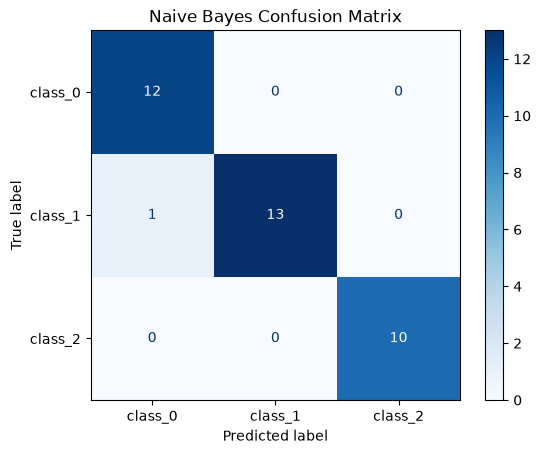

In [14]:
cm = confusion_matrix(y_test, y_pred_nb)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [16]:
y_prob_nb = nb_model.predict_proba(X_test)

probability_df = pd.DataFrame(
    y_prob_nb,
    columns=data.target_names.astype(str),
    index=y_test.index
)

probability_df.head(10)

,class_0,class_1,class_2
10,1.000000e+00,2.856643e-15,2.023284e-43
134,9.478055e-22,7.054703e-05,9.999295e-01
28,9.999985e-01,1.502352e-06,5.587636e-30
121,5.504599e-07,9.999994e-01,2.210641e-52
62,6.835060e-06,9.999932e-01,3.999048e-10
51,1.000000e+00,5.666215e-11,9.994121e-35
7,1.000000e+00,6.358901e-11,1.578528e-29
66,5.684199e-01,4.315801e-01,4.277068e-29
129,1.384410e-12,9.999583e-01,4.167144e-05
166,2.780671e-21,5.188854e-23,1.000000e+00


| Attribute      | Meaning                                             |
| -------------- | --------------------------------------------------- |
| `class_prior_` | Estimated prior probability of each class.          |
| `theta_`       | Estimated mean of every feature for each class.     |
| `var_`         | Estimated variance of every feature for each class. |


In [17]:
print("Class priors:")
print(nb_model.class_prior_)

print("\nFeature means for each class:")
print(nb_model.theta_)

print("\nFeature variances for each class:")
print(nb_model.var_)

Class priors:
[0.33098592 0.40140845 0.26760563]

Feature means for each class:
[[1.37014894e+01 2.06340426e+00 2.45702128e+00 1.71468085e+01
  1.06382979e+02 2.82148936e+00 2.93106383e+00 2.95957447e-01
  1.87829787e+00 5.47851064e+00 1.04702128e+00 3.13595745e+00
  1.09234043e+03]
 [1.22773684e+01 1.91438596e+00 2.23596491e+00 2.04280702e+01
  9.44385965e+01 2.21947368e+00 2.01140351e+00 3.57192982e-01
  1.67596491e+00 2.98298246e+00 1.05010526e+00 2.76789474e+00
  5.26245614e+02]
 [1.31097368e+01 3.32052632e+00 2.44421053e+00 2.14868421e+01
  9.90789474e+01 1.67763158e+00 7.76578947e-01 4.43947368e-01
  1.14263158e+00 7.39499997e+00 6.76052632e-01 1.70842105e+00
  6.22894737e+02]]

Feature variances for each class:
[[2.28754001e-01 5.57665907e-01 5.56133036e-02 7.06343114e+00
  1.16491715e+02 1.11341235e-01 1.36244449e-01 5.13562139e-03
  1.53780981e-01 1.38623485e+00 1.17281972e-02 1.13020728e-01
  4.05381395e+04]
 [2.85450003e-01 1.07239208e+00 8.03143304e-02 1.11280743e+01
  3.19